Libraries imported successfully!

--- Dataset Loaded ---
Dataset shape: (99391, 16)
  country_code country_iso2  country  is_country_group guest_residence_code  \
0           AL           AL  Albania             False                  DOM   
1           AL           AL  Albania             False                  DOM   
2           AL           AL  Albania             False                  DOM   
3           AL           AL  Albania             False                  DOM   
4           AL           AL  Albania             False                  DOM   

    guest_residence measure_code measure accommodation_code  \
0  Domestic country           NR  Number               I551   
1  Domestic country           NR  Number               I551   
2  Domestic country           NR  Number               I551   
3  Domestic country           NR  Number               I551   
4  Domestic country           NR  Number               I551   

                      accommodation  period        date  year 

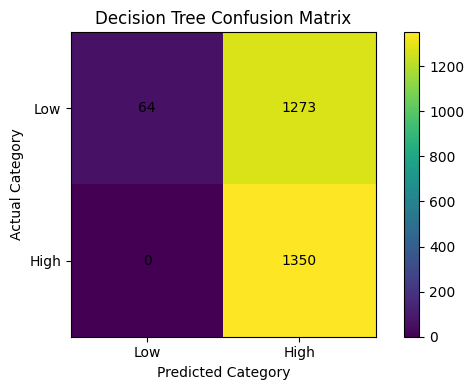


--- Classification Report ---
              precision    recall  f1-score   support

         Low       1.00      0.05      0.09      1337
        High       0.51      1.00      0.68      1350

    accuracy                           0.53      2687
   macro avg       0.76      0.52      0.39      2687
weighted avg       0.76      0.53      0.39      2687



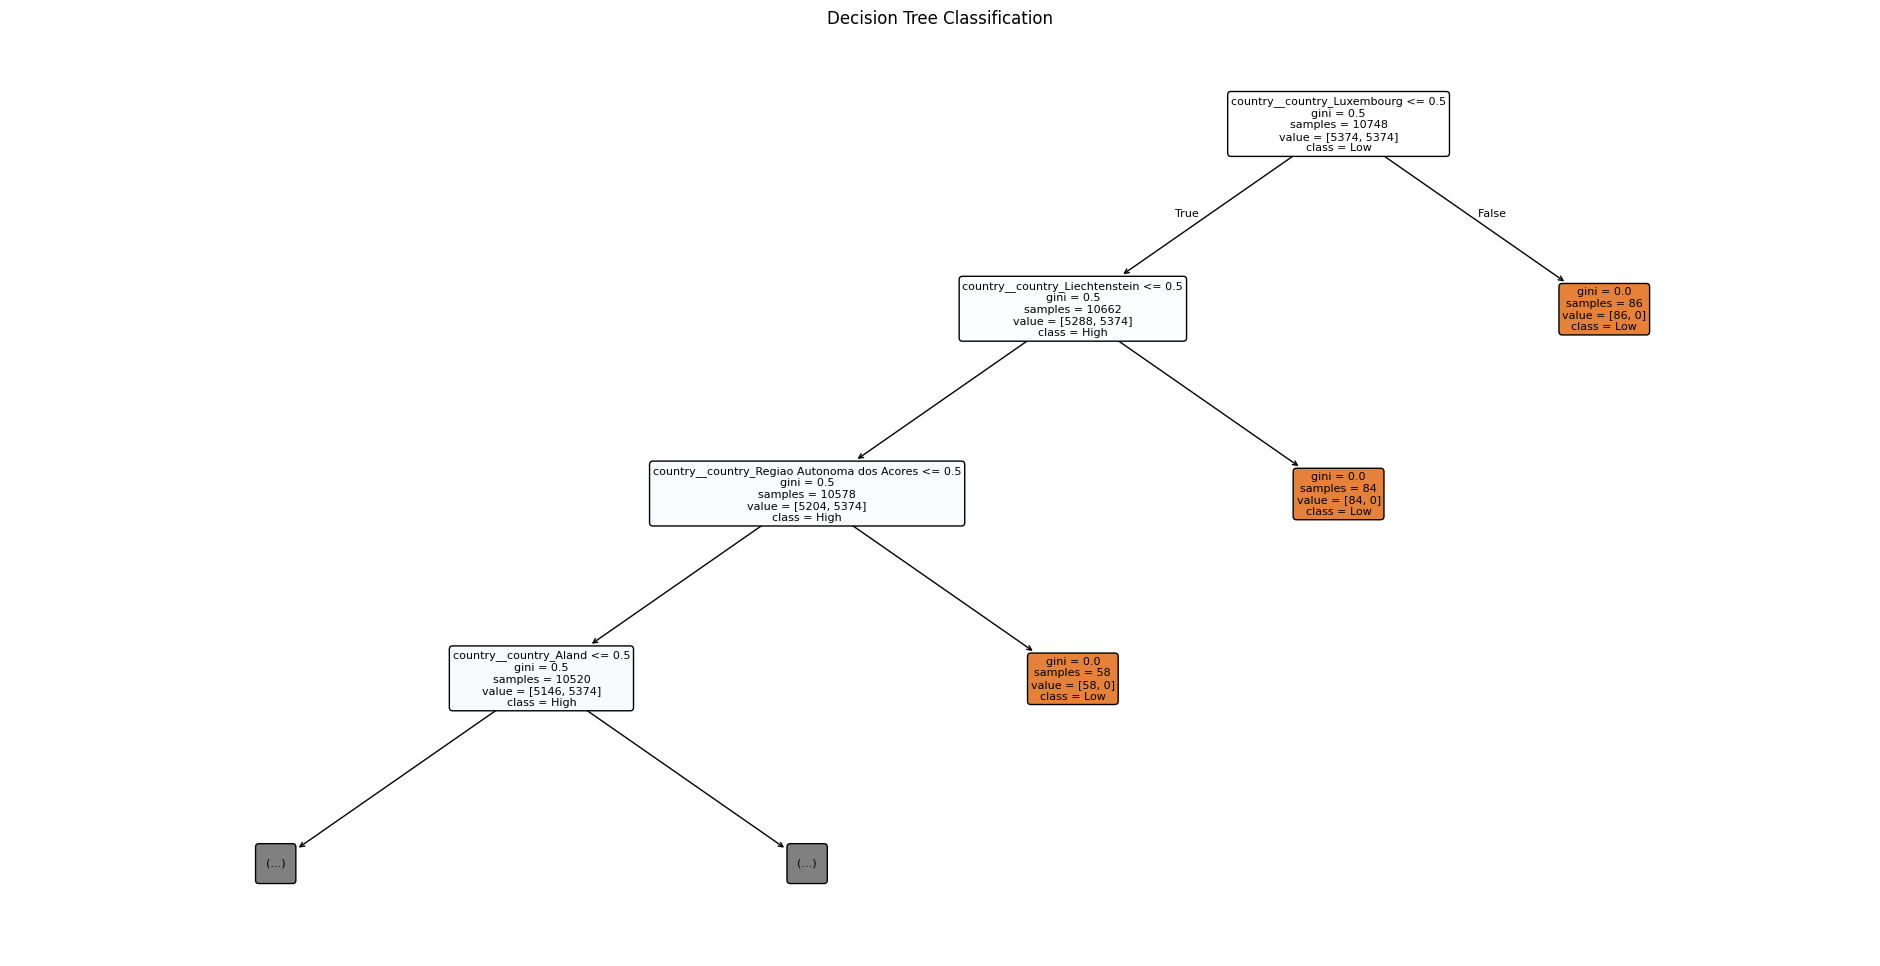


Decision Tree Assignment Completed!


In [4]:

# =====================================================
# MACHINE LEARNING ASSIGNMENT
# DECISION TREE CLASSIFICATION
# =====================================================


# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


# STEP 2: LOAD DATASET

# Update this path according to your Kaggle dataset
df = pd.read_csv(
    "/kaggle/input/datasets/rushik2309/sample-data-set-for-ml/sample data set for ml.csv"
)

print("\n--- Dataset Loaded ---")
print("Dataset shape:", df.shape)
print(df.head())


# STEP 3: EXPLORE DATASET

print("\n--- Dataset Information ---")
df.info()


# STEP 4: CHECK MISSING VALUES

print("\n--- Missing Values ---")
print(df.isnull().sum())


# STEP 5: STATISTICAL ANALYSIS

print("\n--- Tourism Value Statistics ---")
print(df["value"].describe())

print("\nMedian Tourism Value:")
print(df["value"].median())


# STEP 6: FILTER DATASET

ml_df = df[
    (df["measure"] == "Number") &
    (df["is_country_group"] == False) &
    (df["guest_residence"] == "Total") &
    (df["accommodation"] == "Hotels and similar accommodation")
].copy()

print("\n--- Filtered Dataset ---")
print("Dataset shape:", ml_df.shape)

print("Measurement:", ml_df["measure"].unique())
print("Visitor type:", ml_df["guest_residence"].unique())
print("Accommodation:", ml_df["accommodation"].unique())


# STEP 7: SPLIT DATA AND CREATE TARGET VARIABLE

train_df, test_df = train_test_split(
    ml_df,
    test_size=0.20,
    random_state=42
)

# Calculate median from training data only
median_value = train_df["value"].median()

# Create High and Low categories
y_train = (train_df["value"] > median_value).astype(int)
y_test = (test_df["value"] > median_value).astype(int)

print("\n--- Target Categories ---")
print("Training median:", median_value)

print("\nTraining categories:")
print(y_train.value_counts())

print("\nTesting categories:")
print(y_test.value_counts())


# STEP 8: PREPARE INPUT FEATURES

X_train = train_df[["country", "year"]]
X_test = test_df[["country", "year"]]

print("\n--- Input Features ---")
print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)


# STEP 9: ENCODE CATEGORICAL FEATURES

preprocessor = ColumnTransformer(
    transformers=[
        (
            "country",
            OneHotEncoder(handle_unknown="ignore"),
            ["country"]
        ),
        (
            "year",
            "passthrough",
            ["year"]
        )
    ]
)

# Fit on training data
X_train_encoded = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_encoded = preprocessor.transform(X_test)

print("\n--- Encoding Results ---")
print("Training encoded:", X_train_encoded.shape)
print("Testing encoded:", X_test_encoded.shape)


# STEP 10: TRAIN DECISION TREE CLASSIFIER

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train_encoded, y_train)

print("\n--- Decision Tree Training ---")
print("Model trained successfully!")
print("Tree depth:", dt_model.get_depth())
print("Number of leaves:", dt_model.get_n_leaves())


# STEP 11: MAKE PREDICTIONS

y_pred = dt_model.predict(X_test_encoded)

print("\n--- Prediction Results ---")
print("Actual values:")
print(y_test.head(10).tolist())

print("\nPredicted values:")
print(y_pred[:10].tolist())


# STEP 12: MODEL ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("\n--- Model Accuracy ---")
print("Accuracy:", round(accuracy * 100, 2), "%")


# STEP 13: CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

print("\n--- Confusion Matrix ---")
print(cm)

plt.figure(figsize=(6, 4))

plt.imshow(cm, interpolation="nearest")
plt.title("Decision Tree Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Low", "High"])
plt.yticks([0, 1], ["Low", "High"])

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center")

plt.tight_layout()
plt.show()


# STEP 14: CLASSIFICATION REPORT

print("\n--- Classification Report ---")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Low", "High"]
))


# STEP 15: VISUALIZE DECISION TREE

feature_names = (
    preprocessor.get_feature_names_out()
)

plt.figure(figsize=(24, 12))

plot_tree(
    dt_model,
    feature_names=feature_names,
    class_names=["Low", "High"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Classification")
plt.show()


# =====================================================
# END OF MACHINE LEARNING ASSIGNMENT
# =====================================================

print("\nDecision Tree Assignment Completed!")
